---
title: "Exploratory Data Analysis"
format:
    html: 
        code-fold: false
---

<!-- After digesting the instructions, you can delete this cell, these are assignment instructions and do not need to be included in your final submission.  -->

{{< include instructions.qmd >}} 

# Code 

Provide the source code used for this section of the project here.

If you're using a package for code organization, you can import it at this point. However, make sure that the **actual workflow steps**—including data processing, analysis, and other key tasks—are conducted and clearly demonstrated on this page. The goal is to show the technical flow of your project, highlighting how the code is executed to achieve your results.

If relevant, link to additional documentation or external references that explain any complex components. This section should give readers a clear view of how the project is implemented from a technical perspective.

Remember, this page is a technical narrative, NOT just a notebook with a collection of code cells, include in-line Prose, to describe what is going on.

### Now that my data is cleaned, I'm exploring patterns to understand what drives box office success. I'll be looking at budget vs. revenue relationships, genre performance, release timing effects, and more.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# set style for better plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

# load clean data
df = pd.read_csv('../../data/processed-data/tmdb_movies_clean.csv')

print(f"Dataset loaded: {len(df):,} movies")
print(f"Date range: {df['release_year'].min()}-{df['release_year'].max()}")
print(f"Budget range: ${df['budget'].min():,.0f} - ${df['budget'].max():,.0f}")
print(f"Profitable rate: {df['profitable'].mean()*100:.1f}%")

Dataset loaded: 2,691 movies
Date range: 1934-2025
Budget range: $1,000,000 - $583,900,000
Profitable rate: 75.1%


### The fundamental question: does spending more money guarantee higher box office returns? I'm plotting budget against revenue to see if there's a clear relationship or if success is more nuanced.

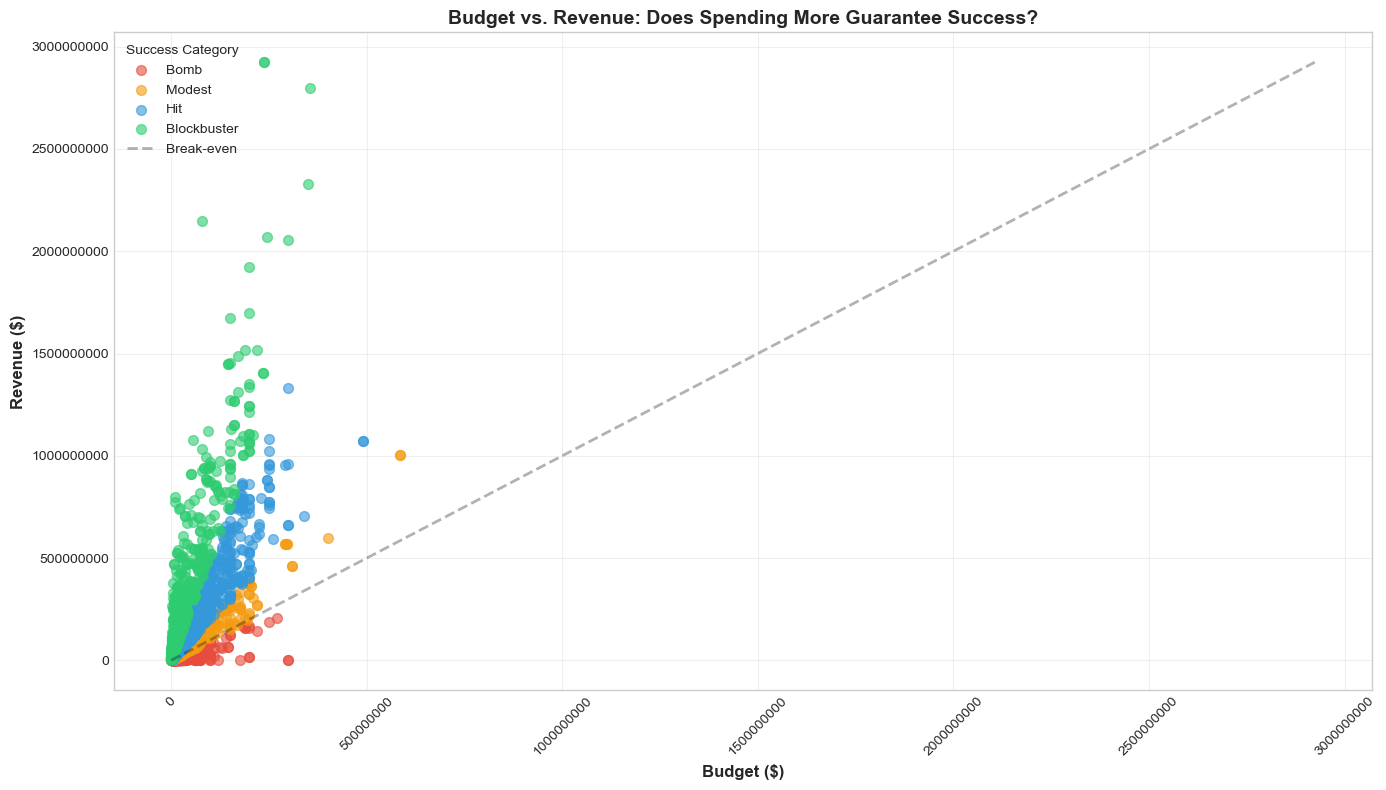


Budget-Revenue Correlation: 0.711
Interpretation: Strong positive relationship


In [3]:
# budget vs revenue scatter plot
plt.figure(figsize=(14, 8))

# create scatter plot colored by success category
colors = {'Bomb': '#e74c3c', 'Modest': '#f39c12', 'Hit': '#3498db', 'Blockbuster': '#2ecc71'}
for category in ['Bomb', 'Modest', 'Hit', 'Blockbuster']:
    mask = df['success_category'] == category
    plt.scatter(df[mask]['budget'], df[mask]['revenue'], 
                alpha=0.6, s=50, label=category, color=colors[category])

# add diagonal line (break-even point)
max_val = max(df['budget'].max(), df['revenue'].max())
plt.plot([0, max_val], [0, max_val], 'k--', alpha=0.3, linewidth=2, label='Break-even')

plt.xlabel('Budget ($)', fontsize=12, fontweight='bold')
plt.ylabel('Revenue ($)', fontsize=12, fontweight='bold')
plt.title('Budget vs. Revenue: Does Spending More Guarantee Success?', fontsize=14, fontweight='bold')
plt.legend(title='Success Category', fontsize=10)
plt.grid(True, alpha=0.3)

# format axes to show millions
ax = plt.gca()
ax.ticklabel_format(style='plain', axis='both')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# calculate correlation
correlation = df['budget'].corr(df['revenue'])
print(f"\nBudget-Revenue Correlation: {correlation:.3f}")
print(f"Interpretation: {'Strong' if abs(correlation) > 0.7 else 'Moderate' if abs(correlation) > 0.4 else 'Weak'} positive relationship")

### While bigger budgets can generate more absolute revenue, I want to know which budget tier delivers ROI. This tells us the most efficient way to spend money.

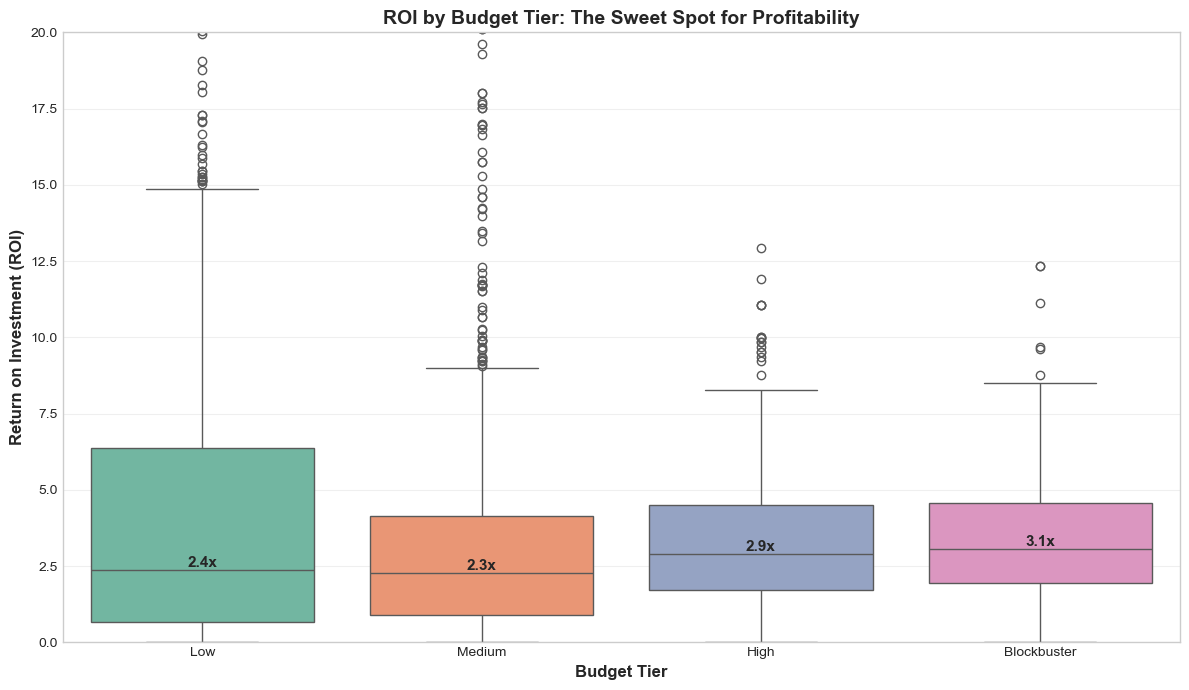


ROI Statistics by Budget Tier:
                 mean    median        std  count
budget_tier                                      
Low          6.025043  2.386717  10.750499   1111
Medium       3.193879  2.264000   3.636934   1057
High         3.563028  2.915495   2.786291    299
Blockbuster  3.570919  3.076213   2.255803    224


In [4]:
# ROI by budget tier
plt.figure(figsize=(12, 7))

# boxplot
bp = sns.boxplot(data=df, x='budget_tier', y='roi', 
                 order=['Low', 'Medium', 'High', 'Blockbuster'],
                 palette='Set2')

# add median values as text
medians = df.groupby('budget_tier')['roi'].median()
order = ['Low', 'Medium', 'High', 'Blockbuster']
for i, tier in enumerate(order):
    plt.text(i, medians[tier], f'{medians[tier]:.1f}x', 
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.xlabel('Budget Tier', fontsize=12, fontweight='bold')
plt.ylabel('Return on Investment (ROI)', fontsize=12, fontweight='bold')
plt.title('ROI by Budget Tier: The Sweet Spot for Profitability', fontsize=14, fontweight='bold')
plt.ylim(0, 20)  # Cap at 20x for better visibility
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Print statistics
print("\nROI Statistics by Budget Tier:")
print("="*60)
roi_stats = df.groupby('budget_tier')['roi'].agg(['mean', 'median', 'std', 'count'])
print(roi_stats.loc[['Low', 'Medium', 'High', 'Blockbuster']])

### Different genres have different success rates and profitability patterns. I'm analyzing which genres consistently deliver profitable films.

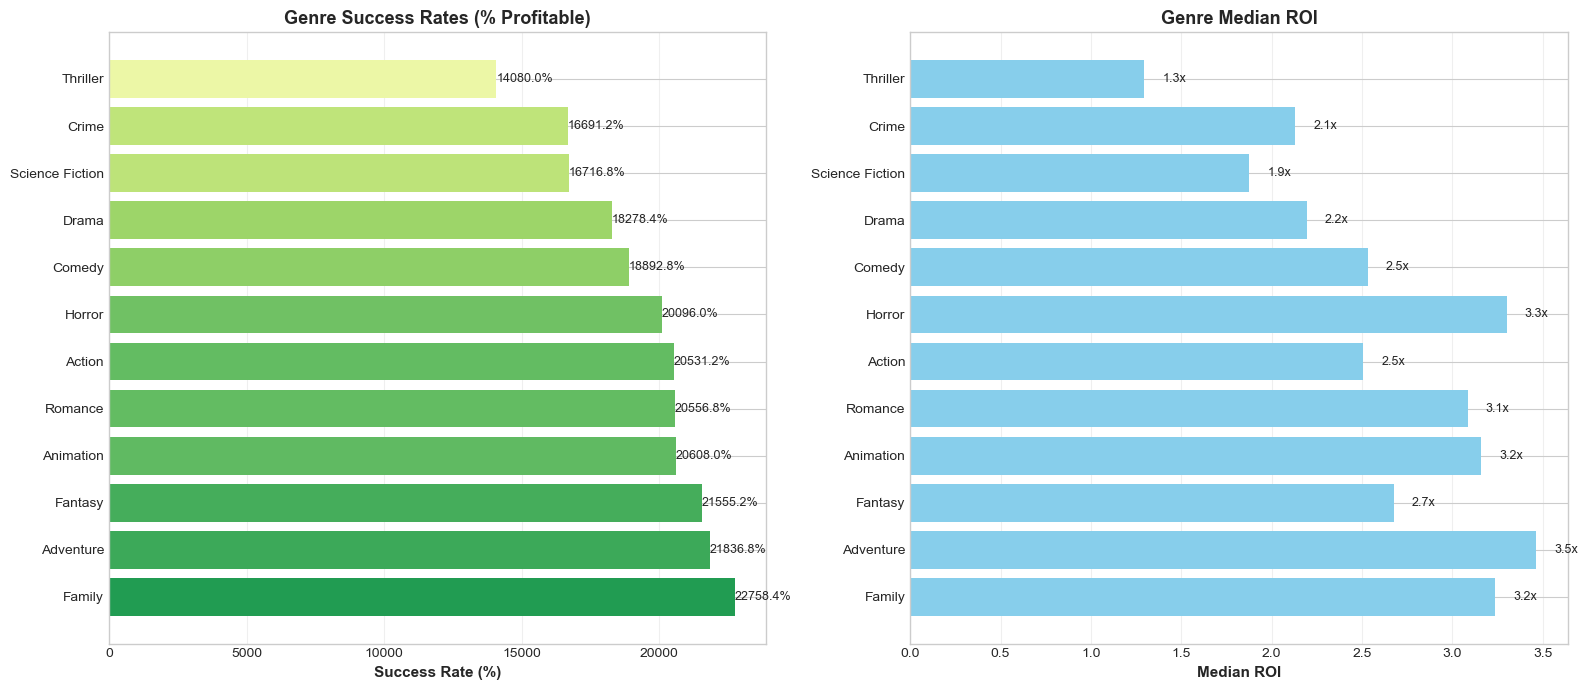


Genre Performance Summary:
                 Success_Rate  Movie_Count  Median_ROI
primary_genre                                         
Family                227.584           90       3.239
Adventure             218.368          190       3.465
Fantasy               215.552           76       2.678
Animation             206.080          164       3.161
Romance               205.568           66       3.086
Action                205.312          511       2.507
Horror                200.960          223       3.302
Comedy                188.928          409       2.531
Drama                 182.784          490       2.194
Science Fiction       167.168          101       1.876
Crime                 166.912          132       2.131
Thriller              140.800          131       1.296


In [7]:
# genre success rates
genre_stats = df.groupby('primary_genre').agg({
    'profitable': ['mean', 'count'],
    'roi': 'median'
}).round(3)

genre_stats.columns = ['Success_Rate', 'Movie_Count', 'Median_ROI']
genre_stats = genre_stats[genre_stats['Movie_Count'] >= 30]  # only genres with 30+ movies
genre_stats = genre_stats.sort_values('Success_Rate', ascending=False)

# figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# plot 1: success rate
colors = plt.cm.RdYlGn(genre_stats['Success_Rate'])
ax1.barh(genre_stats.index, genre_stats['Success_Rate'] * 100, color=colors)
ax1.set_xlabel('Success Rate (%)', fontsize=11, fontweight='bold')
ax1.set_title('Genre Success Rates (% Profitable)', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# percentage labels
for i, (idx, row) in enumerate(genre_stats.iterrows()):
    ax1.text(row['Success_Rate'] * 100 + 1, i, f"{row['Success_Rate']*100:.1f}%", 
             va='center', fontsize=9)

# plot 2: median ROI by genre
ax2.barh(genre_stats.index, genre_stats['Median_ROI'], color='skyblue')
ax2.set_xlabel('Median ROI', fontsize=11, fontweight='bold')
ax2.set_title('Genre Median ROI', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='x')

# ROI labels
for i, (idx, row) in enumerate(genre_stats.iterrows()):
    ax2.text(row['Median_ROI'] + 0.1, i, f"{row['Median_ROI']:.1f}x", 
             va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("\nGenre Performance Summary:")
print("="*70)
print(genre_stats)

### Hollywood has conventional wisdom about release windows - summer for blockbusters, holidays for family films. I'm testing whether release timing actually impacts success rates.

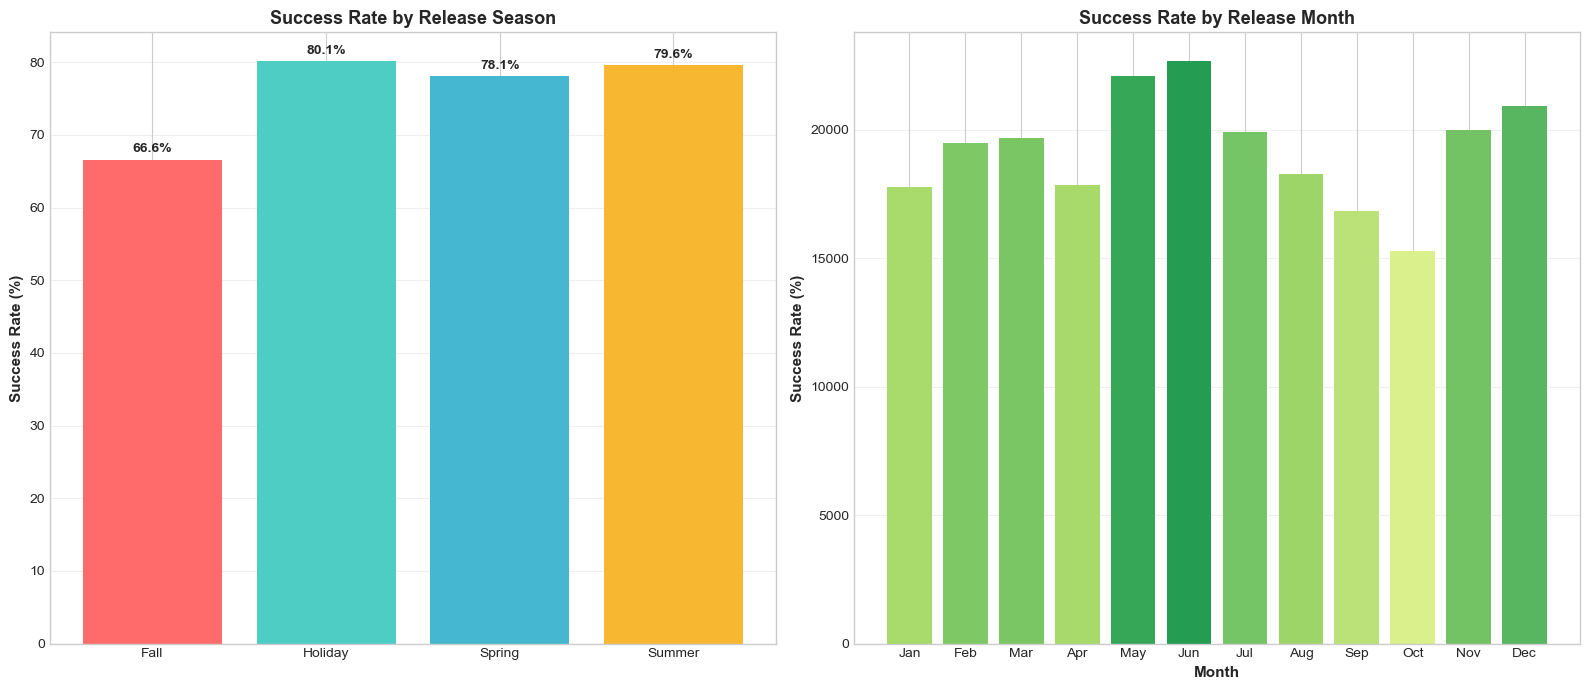


Release Season Statistics:
                Success_Rate  Median_ROI  Count
release_season                                 
Fall                   0.666       1.949    873
Holiday                0.801       2.830    523
Spring                 0.781       2.615    620
Summer                 0.796       2.659    675

Release Month Statistics:
               Success_Rate  Count
release_month                     
1                   177.664    134
2                   194.816    184
3                   196.864    234
4                   178.432    175
5                   220.928    211
6                   226.560    234
7                   198.912    238
8                   182.784    203
9                   168.448    272
10                  152.832    283
11                  199.936    228
12                  209.152    295


In [9]:
# release timing analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# by Season
season_stats = df.groupby('release_season').agg({
    'profitable': 'mean',
    'roi': 'median',
    'movie_id': 'count'
}).round(3)
season_stats.columns = ['Success_Rate', 'Median_ROI', 'Count']

# plot 1: success by season
colors = ['#ff6b6b', '#4ecdc4', '#45b7d1', '#f7b731']
ax1.bar(season_stats.index, season_stats['Success_Rate'] * 100, color=colors)
ax1.set_ylabel('Success Rate (%)', fontsize=11, fontweight='bold')
ax1.set_title('Success Rate by Release Season', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# add labels
for i, (idx, row) in enumerate(season_stats.iterrows()):
    ax1.text(i, row['Success_Rate'] * 100 + 1, f"{row['Success_Rate']*100:.1f}%", 
             ha='center', fontsize=10, fontweight='bold')

# plot 2: by month
month_stats = df.groupby('release_month').agg({
    'profitable': 'mean',
    'movie_id': 'count'
}).round(3)
month_stats.columns = ['Success_Rate', 'Count']

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
colors2 = plt.cm.RdYlGn(month_stats['Success_Rate'])
ax2.bar(range(1, 13), month_stats['Success_Rate'] * 100, color=colors2)
ax2.set_xlabel('Month', fontsize=11, fontweight='bold')
ax2.set_ylabel('Success Rate (%)', fontsize=11, fontweight='bold')
ax2.set_title('Success Rate by Release Month', fontsize=13, fontweight='bold')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(months)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nRelease Season Statistics:")
print("="*60)
print(season_stats)
print("\nRelease Month Statistics:")
print(month_stats)

### Do certain directors consistently deliver hits? Does cast popularity actually predict success?

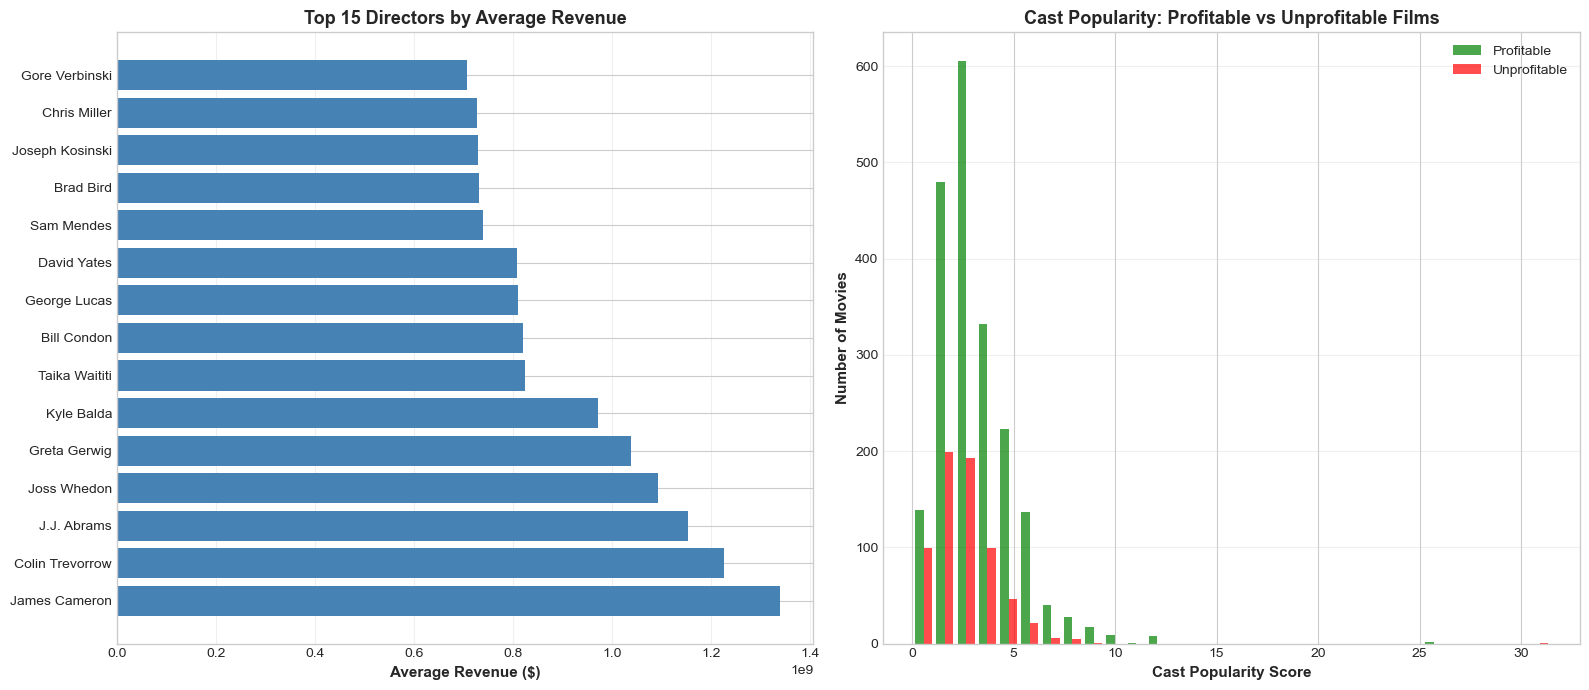


Top 15 Directors:
                  Avg_Revenue  Success_Rate  Movie_Count
director                                                
James Cameron    1.339197e+09          1.00            7
Colin Trevorrow  1.226516e+09          1.00            3
J.J. Abrams      1.153748e+09          1.00            4
Joss Whedon      1.092123e+09          0.75            4
Greta Gerwig     1.036959e+09          1.00            3
Kyle Balda       9.717359e+08          1.00            3
Taika Waititi    8.238345e+08          1.00            3
Bill Condon      8.201582e+08          1.00            6
George Lucas     8.098228e+08          1.00            5
David Yates      8.086040e+08          1.00            5
Sam Mendes       7.386627e+08          1.00            6
Brad Bird        7.314409e+08          0.83            6
Joseph Kosinski  7.282714e+08          1.00            3
Chris Miller     7.272407e+08          1.00            3
Gore Verbinski   7.076818e+08          1.00            4

Average cas

In [11]:
# top directors analysis
director_stats = df.groupby('director').agg({
    'revenue': 'mean',
    'profitable': 'mean',
    'movie_id': 'count'
}).round(2)
director_stats.columns = ['Avg_Revenue', 'Success_Rate', 'Movie_Count']
director_stats = director_stats[director_stats['Movie_Count'] >= 3]  # at least 3 movies
top_directors = director_stats.nlargest(15, 'Avg_Revenue')

# cast popularity vs profitability
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# top directors by average revenue
ax1.barh(range(len(top_directors)), top_directors['Avg_Revenue'], color='steelblue')
ax1.set_yticks(range(len(top_directors)))
ax1.set_yticklabels(top_directors.index)
ax1.set_xlabel('Average Revenue ($)', fontsize=11, fontweight='bold')
ax1.set_title('Top 15 Directors by Average Revenue', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# cast popularity vs profitability
profitable_movies = df[df['profitable'] == 1]
unprofitable_movies = df[df['profitable'] == 0]

ax2.hist([profitable_movies['cast_popularity'], unprofitable_movies['cast_popularity']], 
         bins=30, label=['Profitable', 'Unprofitable'], alpha=0.7, color=['green', 'red'])
ax2.set_xlabel('Cast Popularity Score', fontsize=11, fontweight='bold')
ax2.set_ylabel('Number of Movies', fontsize=11, fontweight='bold')
ax2.set_title('Cast Popularity: Profitable vs Unprofitable Films', fontsize=13, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nTop 15 Directors:")
print("="*70)
print(top_directors)
print(f"\nAverage cast popularity for profitable films: {profitable_movies['cast_popularity'].mean():.1f}")
print(f"Average cast popularity for unprofitable films: {unprofitable_movies['cast_popularity'].mean():.1f}")